In [ ]:
from pathlib import Path
import shutil
import os

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE

DATA_DIR = ROOT / "data" / "raw"
PREP_DIR = ROOT / "data" / "prepared" / "classification"

if PREP_DIR.exists():
    shutil.rmtree(PREP_DIR)
    
for split in ["train", "val", "test"]:
    (PREP_DIR / split).mkdir(parents=True, exist_ok=True)

print("Output folder:", PREP_DIR.resolve())

# Check Source Data

In [2]:
# Check what we have in Train and Val
train_dir = DATA_DIR / "Train"
val_dir = DATA_DIR / "Val"

classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

print("=== SOURCE DATA ===")
for split_name, split_dir in [("Train", train_dir), ("Val", val_dir)]:
    print(f"\n{split_name}:")
    for cls in classes:
        img_folder = split_dir / cls / "images"
        if img_folder.exists():
            n_imgs = len(list(img_folder.glob("*")))
            print(f"  {cls:15} => {n_imgs} images")
        else:
            print(f"  {cls:15} => NOT FOUND")

=== SOURCE DATA ===

Train:
  Glioma          => 1153 images
  Meningioma      => 1449 images
  No Tumor        => 711 images
  Pituitary       => 1424 images

Val:
  Glioma          => 136 images
  Meningioma      => 140 images
  No Tumor        => 100 images
  Pituitary       => 136 images


# Organize

In [3]:
import random
random.seed(42)

def copy_images(source_split, target_split, target_ratio=1.0):
    
    source_dir = DATA_DIR / source_split
    
    for cls in classes:
        src_img = source_dir / cls / "images"
        dst_cls = PREP_DIR / target_split / cls
        dst_cls.mkdir(parents=True, exist_ok=True)
        
        if not src_img.exists():
            continue
            
        files = list(src_img.glob("*"))
        n_copy = int(len(files) * target_ratio)
        
        for f in files[:n_copy]:
            shutil.copy2(f, dst_cls / f.name)
    
    # Count results
    for cls in classes:
        n = len(list((PREP_DIR / target_split / cls).glob("*")))
        print(f"{target_split}/{cls:15} => {n} images")

# Use all Val for validation
copy_images("Val", "val", target_ratio=1.0)

# Split Train into train (85%) and test (15%)
# (Val is already separate but we add test from Train for evaluation)
copy_images("Train", "train", target_ratio=0.85)
copy_images("Train", "test", target_ratio=0.15)

print("\n=== PREPARATION COMPLETE ===")

val/Glioma          => 136 images
val/Meningioma      => 140 images
val/No Tumor        => 100 images
val/Pituitary       => 136 images
train/Glioma          => 980 images
train/Meningioma      => 1231 images
train/No Tumor        => 604 images
train/Pituitary       => 1210 images
test/Glioma          => 172 images
test/Meningioma      => 217 images
test/No Tumor        => 106 images
test/Pituitary       => 213 images

=== PREPARATION COMPLETE ===


# Verify 

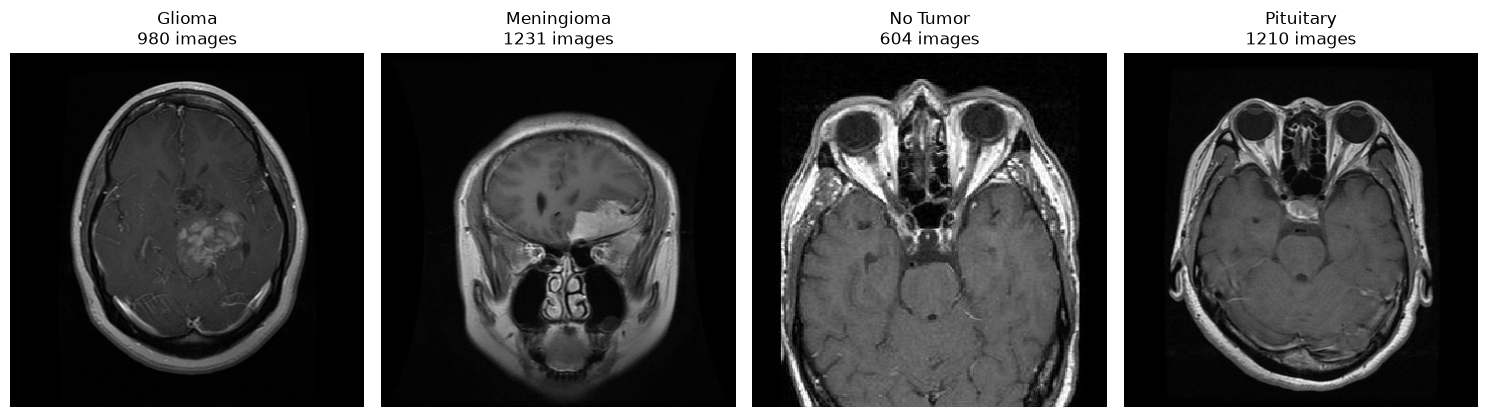


Ready for InceptionV3 training
Use this path:  c:\Users\hamza\Desktop\dev_ai\NeuroVision\data\prepared\classification\train
Validation path: c:\Users\hamza\Desktop\dev_ai\NeuroVision\data\prepared\classification\val


In [4]:
import matplotlib.pyplot as plt
from PIL import Image

# Show one sample from each class in train
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for i, cls in enumerate(classes):
    img_folder = PREP_DIR / "train" / cls
    files = list(img_folder.glob("*"))
    
    if files:
        img = Image.open(files[0])
        axes[i].imshow(img)
        axes[i].set_title(f"{cls}\n{len(files)} images")
        axes[i].axis("off")
    else:
        axes[i].text(0.5, 0.5, "No images", ha="center", va="center")
        axes[i].axis("off")

plt.tight_layout()
plt.show()

print("\nReady for InceptionV3 training")
print("Use this path: ", PREP_DIR / "train")
print("Validation path:", PREP_DIR / "val")